In [1]:
# ============================================================
# CELL 1 — SETUP, ANNOTATIONS AND WINDOW MANIFEST
# ExtraTrees seizure-detection pipeline
# ============================================================

import subprocess
import sys

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "pyedflib", "PyWavelets", "scipy",
    "scikit-learn", "joblib", "seaborn", "tqdm"
])

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

import json
import random
import re
import warnings

from collections import defaultdict
from functools import partial
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import pyedflib
import pywt

from IPython.display import display
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ------------------------------------------------------------
# Directories
# ------------------------------------------------------------

DRIVE_ROOT = Path("/content/drive/MyDrive")
EEG_ROOT = DRIVE_ROOT / "EEG"

# Search both locations because some EDFs are in MyDrive.
SEARCH_ROOTS = [
    EEG_ROOT,
    DRIVE_ROOT
]

OUTPUT_ROOT = (
    EEG_ROOT
    / "model_results"
    / "extratrees_450_features_v1"
)

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("Output directory:", OUTPUT_ROOT)

# ------------------------------------------------------------
# Signal configuration
# ------------------------------------------------------------

SAMPLING_RATE = 256

WINDOW_SECONDS = 5.0
STEP_SECONDS = 2.5

WINDOW_SAMPLES = int(
    SAMPLING_RATE * WINDOW_SECONDS
)

CHANNELS = [
    "FP1-F7", "F7-T7", "T7-P7", "P7-O1",
    "FP1-F3", "F3-C3", "C3-P3", "P3-O1",
    "FP2-F4", "F4-C4", "C4-P4", "P4-O2",
    "FP2-F8", "F8-T8", "T8-P8", "P8-O2",
    "FZ-CZ", "CZ-PZ"
]

FREQUENCY_BANDS = {
    "delta": (0.5, 4.0),
    "theta": (4.0, 8.0),
    "alpha": (8.0, 13.0),
    "beta": (13.0, 30.0),
    "gamma": (30.0, 45.0)
}

# ------------------------------------------------------------
# Patient-separated split
# ------------------------------------------------------------

TRAIN_PATIENTS = {
    "chb01", "chb02", "chb03",
    "chb05", "chb07", "chb08"
}

VALIDATION_PATIENTS = {
    "chb10", "chb23"
}

TEST_PATIENTS = {
    "chb24"
}


def patient_of(path):
    match = re.search(
        r"(chb\d+)",
        Path(path).name.lower()
    )

    return match.group(1) if match else None


def split_of(patient):
    if patient in TRAIN_PATIENTS:
        return "train"

    if patient in VALIDATION_PATIENTS:
        return "validation"

    if patient in TEST_PATIENTS:
        return "test"

    return None


def clean_channel_name(channel_name):
    name = str(channel_name).strip().upper()

    name = (
        name
        .replace("–", "-")
        .replace("—", "-")
        .replace("_", "-")
    )

    name = re.sub(
        r"^EEG[\s\-]*",
        "",
        name
    )

    name = re.sub(
        r"\s+",
        "",
        name
    )

    name = re.sub(
        r"-(REF|LE|AVG)$",
        "",
        name
    )

    return name


# ------------------------------------------------------------
# Parse seizure annotations
# ------------------------------------------------------------

def parse_physionet_summary(summary_path):
    """
    Supports both:
      Seizure 1 Start Time
      Seizure Start Time
    """

    text = Path(summary_path).read_text(
        encoding="utf-8",
        errors="ignore"
    )

    parsed = defaultdict(list)

    current_file = None
    pending_start = None

    for raw_line in text.splitlines():
        line = raw_line.strip()

        file_match = re.search(
            r"File\s+Name\s*:\s*(\S+\.edf)",
            line,
            flags=re.IGNORECASE
        )

        if file_match:
            current_file = (
                file_match
                .group(1)
                .strip()
                .lower()
            )

            pending_start = None
            continue

        if current_file is None:
            continue

        start_match = re.search(
            r"Seizure(?:\s+\d+)?"
            r"\s+Start\s+Time\s*:\s*"
            r"([0-9.]+)\s*seconds?",
            line,
            flags=re.IGNORECASE
        )

        if start_match:
            pending_start = float(
                start_match.group(1)
            )
            continue

        end_match = re.search(
            r"Seizure(?:\s+\d+)?"
            r"\s+End\s+Time\s*:\s*"
            r"([0-9.]+)\s*seconds?",
            line,
            flags=re.IGNORECASE
        )

        if (
            end_match
            and pending_start is not None
        ):
            seizure_end = float(
                end_match.group(1)
            )

            if seizure_end > pending_start:
                parsed[current_file].append(
                    (
                        pending_start,
                        seizure_end
                    )
                )

            pending_start = None

    return dict(parsed)


summary_paths = []

for search_root in SEARCH_ROOTS:
    if search_root.exists():
        summary_paths.extend(
            search_root.rglob("*summary*.txt")
        )

summary_paths = sorted(set(summary_paths))

print("Summary files:", len(summary_paths))

if not summary_paths:
    raise RuntimeError(
        "No CHB-MIT summary files were found."
    )

merged_events = defaultdict(set)

for summary_path in summary_paths:
    try:
        parsed_summary = (
            parse_physionet_summary(
                summary_path
            )
        )

        for filename, intervals in (
            parsed_summary.items()
        ):
            for interval in intervals:
                merged_events[
                    filename.lower()
                ].add(
                    tuple(map(float, interval))
                )

    except Exception as error:
        print(
            "Summary skipped:",
            summary_path,
            error
        )

events_by_file = {
    filename: sorted(intervals)
    for filename, intervals
    in merged_events.items()
}

print(
    "Files with seizure annotations:",
    len(events_by_file)
)

# ------------------------------------------------------------
# Validate EDF and required channels
# ------------------------------------------------------------

def validate_edf_file(edf_path):
    reader = None

    try:
        edf_path = Path(edf_path)

        if (
            not edf_path.exists()
            or edf_path.stat().st_size < 1024
        ):
            return False, "missing or incomplete"

        reader = pyedflib.EdfReader(
            str(edf_path)
        )

        original_names = (
            reader.getSignalLabels()
        )

        normalized_names = [
            clean_channel_name(name)
            for name in original_names
        ]

        for required_channel in CHANNELS:
            required = clean_channel_name(
                required_channel
            )

            matches = [
                index
                for index, available
                in enumerate(normalized_names)
                if (
                    available == required
                    or available.startswith(
                        required + "-"
                    )
                )
            ]

            if not matches:
                return (
                    False,
                    f"missing channel {required_channel}"
                )

        sample_counts = reader.getNSamples()

        if (
            len(sample_counts) == 0
            or int(sample_counts[0]) <= 0
        ):
            return False, "no samples"

        check_length = min(
            256,
            int(sample_counts[0])
        )

        check_signal = reader.readSignal(
            0,
            0,
            check_length
        )

        if not np.all(
            np.isfinite(check_signal)
        ):
            return False, "invalid samples"

        return True, "readable"

    except Exception as error:
        return (
            False,
            f"{type(error).__name__}: {error}"
        )

    finally:
        if reader is not None:
            try:
                reader.close()
            except Exception:
                pass


# ------------------------------------------------------------
# Find readable EDF recordings
# ------------------------------------------------------------

edf_candidates = defaultdict(list)

for search_root in SEARCH_ROOTS:
    if not search_root.exists():
        continue

    for edf_path in search_root.rglob("*.edf"):
        patient = patient_of(edf_path)

        if split_of(patient) is not None:
            edf_candidates[
                edf_path.name.lower()
            ].append(edf_path)

edf_files = []
unusable_files = []

for filename, candidates in sorted(
    edf_candidates.items()
):
    candidates = sorted(
        candidates,
        key=lambda path: (
            "/EEG/" not in str(path),
            -path.stat().st_size
            if path.exists()
            else 0
        )
    )

    selected_path = None
    errors = []

    for candidate in candidates:
        usable, message = validate_edf_file(
            candidate
        )

        if usable:
            selected_path = candidate
            break

        errors.append(
            f"{candidate}: {message}"
        )

    if selected_path is None:
        unusable_files.append(
            {
                "file": filename,
                "errors": " | ".join(errors)
            }
        )
    else:
        edf_files.append(selected_path)

print(
    "Usable unique EDF recordings:",
    len(edf_files)
)

display(
    pd.Series(
        [
            patient_of(path)
            for path in edf_files
        ],
        name="recordings"
    )
    .value_counts()
    .sort_index()
    .to_frame()
)

if unusable_files:
    unusable_table = pd.DataFrame(
        unusable_files
    )

    print("Excluded EDF files:")
    display(unusable_table)

    unusable_table.to_csv(
        OUTPUT_ROOT
        / "excluded_edf_files.csv",
        index=False
    )

# ------------------------------------------------------------
# Create the natural-distribution manifest
# ------------------------------------------------------------

manifest_rows = []

for recording_number, edf_path in enumerate(
    edf_files,
    start=1
):
    reader = None

    try:
        reader = pyedflib.EdfReader(
            str(edf_path)
        )

        duration = (
            float(reader.getNSamples()[0])
            / float(reader.getSampleFrequency(0))
        )

    finally:
        if reader is not None:
            reader.close()

    patient = patient_of(edf_path)
    split_name = split_of(patient)

    seizure_intervals = events_by_file.get(
        edf_path.name.lower(),
        []
    )

    window_starts = np.arange(
        0.0,
        duration
        - WINDOW_SECONDS
        + 1e-9,
        STEP_SECONDS
    )

    for start_time in window_starts:
        end_time = (
            start_time
            + WINDOW_SECONDS
        )

        label = int(
            any(
                start_time < seizure_end
                and end_time > seizure_start
                for seizure_start, seizure_end
                in seizure_intervals
            )
        )

        manifest_rows.append(
            {
                "path": str(edf_path),
                "file": edf_path.name,
                "patient": patient,
                "split": split_name,
                "start": float(start_time),
                "end": float(end_time),
                "label": label
            }
        )

    if recording_number % 10 == 0:
        print(
            f"Manifest progress: "
            f"{recording_number}/"
            f"{len(edf_files)}"
        )

full_manifest = pd.DataFrame(
    manifest_rows
).reset_index(drop=True)

if full_manifest.empty:
    raise RuntimeError(
        "No EEG windows were created."
    )


def show_distribution(table):
    result = (
        table
        .groupby("split")["label"]
        .agg(
            total_windows="size",
            seizure_windows="sum"
        )
    )

    result["background_windows"] = (
        result["total_windows"]
        - result["seizure_windows"]
    )

    result["seizure_percentage"] = (
        100.0
        * result["seizure_windows"]
        / result["total_windows"]
    )

    return result[
        [
            "background_windows",
            "seizure_windows",
            "total_windows",
            "seizure_percentage"
        ]
    ]


for split_name in (
    "train",
    "validation",
    "test"
):
    labels = full_manifest.loc[
        full_manifest["split"] == split_name,
        "label"
    ]

    if (
        labels.empty
        or labels.nunique() != 2
    ):
        raise RuntimeError(
            f"{split_name} does not "
            "contain both classes."
        )

print("\nNatural distribution:")

display(
    show_distribution(
        full_manifest
    )
)

full_manifest.to_csv(
    OUTPUT_ROOT
    / "complete_window_manifest.csv",
    index=False
)

print("\nCELL 1 COMPLETE")

Mounted at /content/drive
Output directory: /content/drive/MyDrive/EEG/model_results/extratrees_450_features_v1
Summary files: 11
Files with seizure annotations: 59
Usable unique EDF recordings: 87


,count
recordings,
chb01,18
chb02,13
chb03,5
chb05,3
chb07,3
chb08,7
chb10,9
chb23,7
chb24,22


Manifest progress: 10/87
Manifest progress: 20/87
Manifest progress: 30/87
Manifest progress: 40/87
Manifest progress: 50/87
Manifest progress: 60/87
Manifest progress: 70/87
Manifest progress: 80/87

Natural distribution:


,background_windows,seizure_windows,total_windows,seizure_percentage
split,,,,
test,30412,232,30644,0.757081
train,69693,767,70460,1.088561
validation,56769,371,57140,0.649282



CELL 1 COMPLETE


In [2]:
# ============================================================
# CELL 2 — TRAINING SELECTION AND 450-FEATURE EXTRACTION
# ============================================================

from fractions import Fraction

from scipy.signal import (
    butter,
    resample_poly,
    sosfiltfilt,
    welch
)

from scipy.stats import (
    kurtosis,
    skew
)

TRAIN_BACKGROUND_RATIO = 10
FORCE_REEXTRACT = False

# ------------------------------------------------------------
# Training-only background reduction
# ------------------------------------------------------------

complete_training = full_manifest[
    full_manifest["split"] == "train"
].copy()

validation_manifest = full_manifest[
    full_manifest["split"] == "validation"
].copy().reset_index(drop=True)

test_manifest = full_manifest[
    full_manifest["split"] == "test"
].copy().reset_index(drop=True)

selected_training_parts = []
selection_rows = []

for patient_number, patient in enumerate(
    sorted(TRAIN_PATIENTS)
):
    patient_table = complete_training[
        complete_training["patient"] == patient
    ].copy()

    seizure_rows = patient_table[
        patient_table["label"] == 1
    ].copy()

    background_rows = patient_table[
        patient_table["label"] == 0
    ].copy()

    if len(seizure_rows) == 0:
        requested_background = min(
            500,
            len(background_rows)
        )
    else:
        requested_background = min(
            len(background_rows),
            TRAIN_BACKGROUND_RATIO
            * len(seizure_rows)
        )

    selected_background = (
        background_rows.sample(
            n=requested_background,
            replace=False,
            random_state=(
                SEED + patient_number
            )
        )
    )

    selected_patient = pd.concat(
        [
            seizure_rows,
            selected_background
        ],
        ignore_index=True
    )

    selected_training_parts.append(
        selected_patient
    )

    selection_rows.append(
        {
            "patient": patient,
            "seizure_windows": len(
                seizure_rows
            ),
            "selected_background": len(
                selected_background
            ),
            "original_background": len(
                background_rows
            )
        }
    )

training_manifest = pd.concat(
    selected_training_parts,
    ignore_index=True
)

training_manifest = (
    training_manifest
    .sample(
        frac=1.0,
        random_state=SEED
    )
    .reset_index(drop=True)
)

print("Training selection:")

display(
    pd.DataFrame(selection_rows)
)

combined_manifest = pd.concat(
    [
        training_manifest.assign(
            split="train"
        ),
        validation_manifest,
        test_manifest
    ],
    ignore_index=True
)

print("\nDistribution used by model:")

display(
    show_distribution(
        combined_manifest
    )
)

training_manifest.to_csv(
    OUTPUT_ROOT
    / "training_manifest_10_to_1.csv",
    index=False
)

validation_manifest.to_csv(
    OUTPUT_ROOT
    / "validation_manifest_untouched.csv",
    index=False
)

test_manifest.to_csv(
    OUTPUT_ROOT
    / "test_manifest_untouched_chb24.csv",
    index=False
)

# ------------------------------------------------------------
# Filter
# ------------------------------------------------------------

FILTER_SOS = butter(
    4,
    [0.5, 45.0],
    btype="bandpass",
    fs=SAMPLING_RATE,
    output="sos"
)


def read_filtered_recording(path_string):
    reader = pyedflib.EdfReader(
        str(path_string)
    )

    try:
        original_names = (
            reader.getSignalLabels()
        )

        normalized_names = [
            clean_channel_name(name)
            for name in original_names
        ]

        channel_indices = []

        for required_channel in CHANNELS:
            required = clean_channel_name(
                required_channel
            )

            matches = [
                index
                for index, available
                in enumerate(normalized_names)
                if (
                    available == required
                    or available.startswith(
                        required + "-"
                    )
                )
            ]

            if not matches:
                raise ValueError(
                    f"{Path(path_string).name}: "
                    f"missing {required_channel}"
                )

            channel_indices.append(
                matches[0]
            )

        signals = [
            reader.readSignal(
                channel_index
            ).astype(np.float32)
            for channel_index
            in channel_indices
        ]

        rates = [
            float(
                reader.getSampleFrequency(
                    channel_index
                )
            )
            for channel_index
            in channel_indices
        ]

    finally:
        reader.close()

    processed_signals = []

    for signal, sampling_rate in zip(
        signals,
        rates
    ):
        if np.isclose(
            sampling_rate,
            SAMPLING_RATE
        ):
            processed_signal = signal

        else:
            ratio = Fraction(
                SAMPLING_RATE
                / sampling_rate
            ).limit_denominator(1000)

            processed_signal = resample_poly(
                signal,
                ratio.numerator,
                ratio.denominator
            )

        processed_signals.append(
            processed_signal.astype(
                np.float32
            )
        )

    minimum_length = min(
        len(signal)
        for signal in processed_signals
    )

    recording = np.stack(
        [
            signal[:minimum_length]
            for signal
            in processed_signals
        ]
    ).astype(np.float32)

    filtered = sosfiltfilt(
        FILTER_SOS,
        recording,
        axis=1
    ).astype(np.float32)

    return filtered


# ------------------------------------------------------------
# Feature names: 25 per channel × 18 = 450
# ------------------------------------------------------------

PER_CHANNEL_FEATURES = [
    "mean",
    "standard_deviation",
    "variance",
    "rms",
    "minimum",
    "maximum",
    "peak_to_peak",
    "skewness",
    "kurtosis",
    "line_length",

    "hjorth_activity",
    "hjorth_mobility",
    "hjorth_complexity",

    "relative_delta_power",
    "relative_theta_power",
    "relative_alpha_power",
    "relative_beta_power",
    "relative_gamma_power",
    "spectral_entropy",

    "wavelet_energy_a5",
    "wavelet_energy_d5",
    "wavelet_energy_d4",
    "wavelet_energy_d3",
    "wavelet_energy_d2",
    "wavelet_energy_d1"
]

FEATURE_NAMES = [
    f"{channel}_{feature}"
    for channel in CHANNELS
    for feature in PER_CHANNEL_FEATURES
]

assert len(FEATURE_NAMES) == 450

# ------------------------------------------------------------
# Extract exactly 25 features from one channel
# ------------------------------------------------------------

def extract_channel_features(signal):
    signal = np.asarray(
        signal,
        dtype=np.float64
    )

    epsilon = 1e-12

    first_difference = np.diff(signal)
    second_difference = np.diff(
        first_difference
    )

    variance = float(
        np.var(signal)
    )

    difference_variance = float(
        np.var(first_difference)
    )

    second_difference_variance = float(
        np.var(second_difference)
    )

    hjorth_activity = variance

    hjorth_mobility = np.sqrt(
        difference_variance
        / (variance + epsilon)
    )

    hjorth_complexity = (
        np.sqrt(
            second_difference_variance
            / (
                difference_variance
                + epsilon
            )
        )
        / (hjorth_mobility + epsilon)
    )

    statistical_features = [
        np.mean(signal),
        np.std(signal),
        variance,
        np.sqrt(
            np.mean(signal ** 2)
        ),
        np.min(signal),
        np.max(signal),
        np.ptp(signal),
        skew(
            signal,
            bias=False
        ),
        kurtosis(
            signal,
            fisher=True,
            bias=False
        ),
        np.sum(
            np.abs(first_difference)
        )
    ]

    hjorth_features = [
        hjorth_activity,
        hjorth_mobility,
        hjorth_complexity
    ]

    frequencies, power = welch(
        signal,
        fs=SAMPLING_RATE,
        nperseg=min(
            512,
            len(signal)
        ),
        noverlap=min(
            256,
            len(signal) // 2
        )
    )

    total_mask = (
        (frequencies >= 0.5)
        & (frequencies <= 45.0)
    )

    total_power = np.trapz(
        power[total_mask],
        frequencies[total_mask]
    ) + epsilon

    spectral_features = []

    for low_frequency, high_frequency in (
        FREQUENCY_BANDS.values()
    ):
        band_mask = (
            (frequencies >= low_frequency)
            & (frequencies < high_frequency)
        )

        band_power = np.trapz(
            power[band_mask],
            frequencies[band_mask]
        )

        spectral_features.append(
            band_power / total_power
        )

    normalized_power = (
        power[total_mask]
        / (
            np.sum(power[total_mask])
            + epsilon
        )
    )

    spectral_entropy = (
        -np.sum(
            normalized_power
            * np.log2(
                normalized_power
                + epsilon
            )
        )
        / np.log2(
            len(normalized_power)
            + epsilon
        )
    )

    spectral_features.append(
        spectral_entropy
    )

    wavelet_coefficients = pywt.wavedec(
        signal,
        wavelet="db4",
        level=5
    )

    wavelet_features = [
        np.log10(
            np.mean(
                coefficient ** 2
            ) + epsilon
        )
        for coefficient
        in wavelet_coefficients
    ]

    features = np.asarray(
        statistical_features
        + hjorth_features
        + spectral_features
        + wavelet_features,
        dtype=np.float32
    )

    if features.shape != (25,):
        raise RuntimeError(
            "Expected 25 channel features, "
            f"received {features.shape}"
        )

    return np.nan_to_num(
        features,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )


def extract_window_features(window):
    feature_vector = np.concatenate(
        [
            extract_channel_features(
                window[channel_index]
            )
            for channel_index
            in range(len(CHANNELS))
        ]
    ).astype(np.float32)

    if feature_vector.shape != (450,):
        raise RuntimeError(
            "Expected 450 features, "
            f"received {feature_vector.shape}"
        )

    return feature_vector


# ------------------------------------------------------------
# Extract one complete split
# ------------------------------------------------------------

def extract_split_features(
    manifest,
    split_name
):
    cache_path = (
        OUTPUT_ROOT
        / f"{split_name}_features.npz"
    )

    if (
        cache_path.exists()
        and not FORCE_REEXTRACT
    ):
        saved = np.load(
            cache_path
        )

        if len(saved["y"]) == len(manifest):
            print(
                f"Loaded cached {split_name} "
                "features."
            )

            return (
                saved["X"],
                saved["y"]
            )

    manifest = (
        manifest
        .reset_index(drop=True)
        .copy()
    )

    features = np.zeros(
        (
            len(manifest),
            450
        ),
        dtype=np.float32
    )

    labels = manifest[
        "label"
    ].to_numpy(
        dtype=np.int8
    )

    grouped = manifest.groupby(
        "path",
        sort=False
    )

    for path_string, group in tqdm(
        grouped,
        total=manifest["path"].nunique(),
        desc=f"Extracting {split_name}"
    ):
        recording = read_filtered_recording(
            path_string
        )

        for row_index in group.index:
            start_time = float(
                manifest.loc[
                    row_index,
                    "start"
                ]
            )

            first_sample = int(
                round(
                    start_time
                    * SAMPLING_RATE
                )
            )

            final_sample = (
                first_sample
                + WINDOW_SAMPLES
            )

            window = recording[
                :,
                first_sample:final_sample
            ]

            if window.shape != (
                18,
                WINDOW_SAMPLES
            ):
                raise RuntimeError(
                    f"Incomplete window: "
                    f"{manifest.loc[row_index, 'file']} "
                    f"{window.shape}"
                )

            features[row_index] = (
                extract_window_features(
                    window
                )
            )

        del recording

    np.savez_compressed(
        cache_path,
        X=features,
        y=labels
    )

    print(
        f"Saved {split_name} features:",
        cache_path
    )

    return features, labels


X_train, y_train = extract_split_features(
    training_manifest,
    "train_10_to_1"
)

X_validation, y_validation = (
    extract_split_features(
        validation_manifest,
        "validation_full"
    )
)

X_test, y_test = extract_split_features(
    test_manifest,
    "chb24_test_full"
)

print("\nFeature shapes:")
print("Train:", X_train.shape)
print("Validation:", X_validation.shape)
print("Test:", X_test.shape)

assert X_train.shape[1] == 450
assert X_validation.shape[1] == 450
assert X_test.shape[1] == 450

print("\nCELL 2 COMPLETE")

Training selection:


,patient,seizure_windows,selected_background,original_background
0,chb01,108,1080,25794
1,chb02,75,750,17575
2,chb03,74,740,7121
3,chb05,94,940,4227
4,chb07,40,400,5279
5,chb08,376,3760,9697



Distribution used by model:


,background_windows,seizure_windows,total_windows,seizure_percentage
split,,,,
test,30412,232,30644,0.757081
train,7670,767,8437,9.090909
validation,56769,371,57140,0.649282


Extracting train_10_to_1:   0%|          | 0/49 [00:00<?, ?it/s]

Saved train_10_to_1 features: /content/drive/MyDrive/EEG/model_results/extratrees_450_features_v1/train_10_to_1_features.npz


Extracting validation_full:   0%|          | 0/16 [00:00<?, ?it/s]

Saved validation_full features: /content/drive/MyDrive/EEG/model_results/extratrees_450_features_v1/validation_full_features.npz


Extracting chb24_test_full:   0%|          | 0/22 [00:00<?, ?it/s]

Saved chb24_test_full features: /content/drive/MyDrive/EEG/model_results/extratrees_450_features_v1/chb24_test_full_features.npz

Feature shapes:
Train: (8437, 450)
Validation: (57140, 450)
Test: (30644, 450)

CELL 2 COMPLETE


In [3]:
# ============================================================
# CELL 3 — TRAINING-ONLY FEATURE PREPARATION
# ============================================================

from sklearn.feature_selection import (
    SelectKBest,
    VarianceThreshold,
    mutual_info_classif
)

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

NUMBER_OF_SELECTED_FEATURES = 200

mutual_information = partial(
    mutual_info_classif,
    random_state=SEED
)

feature_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "variance_filter",
            VarianceThreshold(
                threshold=1e-10
            )
        ),
        (
            "feature_selector",
            SelectKBest(
                score_func=mutual_information,
                k=NUMBER_OF_SELECTED_FEATURES
            )
        )
    ]
)

# Fit only on training patients.
X_train_selected = (
    feature_preprocessor.fit_transform(
        X_train,
        y_train
    )
)

X_validation_selected = (
    feature_preprocessor.transform(
        X_validation
    )
)

X_test_selected = (
    feature_preprocessor.transform(
        X_test
    )
)

joblib.dump(
    feature_preprocessor,
    OUTPUT_ROOT
    / "feature_preprocessor.joblib"
)

# Save selected feature names.
variance_support = (
    feature_preprocessor
    .named_steps["variance_filter"]
    .get_support()
)

names_after_variance = np.asarray(
    FEATURE_NAMES
)[variance_support]

selection_support = (
    feature_preprocessor
    .named_steps["feature_selector"]
    .get_support()
)

selected_feature_names = (
    names_after_variance[
        selection_support
    ]
)

pd.DataFrame(
    {
        "selected_feature": (
            selected_feature_names
        )
    }
).to_csv(
    OUTPUT_ROOT
    / "selected_feature_names.csv",
    index=False
)

print(
    "Original features:",
    X_train.shape[1]
)

print(
    "Selected features:",
    X_train_selected.shape[1]
)

print(
    "Training shape:",
    X_train_selected.shape
)

print(
    "Validation shape:",
    X_validation_selected.shape
)

print(
    "Test shape:",
    X_test_selected.shape
)

print("\nCELL 3 COMPLETE")

Original features: 450
Selected features: 200
Training shape: (8437, 200)
Validation shape: (57140, 200)
Test shape: (30644, 200)

CELL 3 COMPLETE


In [4]:
# ============================================================
# CELL 4 — EXTRATREES AND DETECTION-PARAMETER SEARCH
# Uses CHB10 + CHB23 validation data only
# ============================================================

from sklearn.ensemble import (
    ExtraTreesClassifier
)

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)

from sklearn.model_selection import (
    ParameterSampler
)


def classification_metrics(
    labels,
    probabilities,
    threshold
):
    predictions = (
        probabilities >= threshold
    ).astype(np.int8)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / max(tn + fp, 1)
    )

    return {
        "accuracy": accuracy_score(
            labels,
            predictions
        ),
        "balanced_accuracy": (
            balanced_accuracy_score(
                labels,
                predictions
            )
        ),
        "sensitivity": recall_score(
            labels,
            predictions,
            zero_division=0
        ),
        "specificity": specificity,
        "precision": precision_score(
            labels,
            predictions,
            zero_division=0
        ),
        "f1": f1_score(
            labels,
            predictions,
            zero_division=0
        ),
        "roc_auc": roc_auc_score(
            labels,
            probabilities
        ),
        "pr_auc": (
            average_precision_score(
                labels,
                probabilities
            )
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "predictions": predictions
    }


def apply_consecutive_rule(
    metadata,
    predictions,
    consecutive_windows
):
    metadata = (
        metadata
        .reset_index(drop=True)
        .copy()
    )

    predictions = np.asarray(
        predictions,
        dtype=np.int8
    )

    confirmed = np.zeros_like(
        predictions
    )

    for _, group in metadata.groupby(
        "file",
        sort=False
    ):
        positions = (
            group
            .sort_values("start")
            .index
            .to_numpy()
        )

        record_predictions = (
            predictions[positions]
        )

        record_confirmed = np.zeros_like(
            record_predictions
        )

        for index in range(
            consecutive_windows - 1,
            len(record_predictions)
        ):
            recent = record_predictions[
                index
                - consecutive_windows
                + 1:
                index + 1
            ]

            if np.all(recent == 1):
                record_confirmed[index] = 1

        confirmed[
            positions
        ] = record_confirmed

    return confirmed


def intervals_overlap(
    first_interval,
    second_interval
):
    return (
        first_interval[0]
        < second_interval[1]
        and first_interval[1]
        > second_interval[0]
    )


def calculate_event_metrics(
    metadata,
    alarm_predictions
):
    evaluation = (
        metadata
        .reset_index(drop=True)
        .copy()
    )

    evaluation["alarm"] = np.asarray(
        alarm_predictions,
        dtype=np.int8
    )

    true_events = 0
    detected_events = 0
    false_alarm_events = 0
    background_seconds = 0.0

    for filename, group in (
        evaluation.groupby(
            "file",
            sort=False
        )
    ):
        group = (
            group
            .sort_values("start")
            .reset_index(drop=True)
        )

        true_intervals = (
            events_by_file.get(
                str(filename).lower(),
                []
            )
        )

        true_events += len(
            true_intervals
        )

        background_seconds += (
            float(
                (
                    group["label"] == 0
                ).sum()
            )
            * STEP_SECONDS
        )

        alarm_values = (
            group["alarm"]
            .to_numpy(dtype=np.int8)
        )

        alarm_intervals = []
        run_start = None

        for index, value in enumerate(
            alarm_values
        ):
            if (
                value == 1
                and run_start is None
            ):
                run_start = index

            if (
                value == 0
                and run_start is not None
            ):
                alarm_intervals.append(
                    (
                        float(
                            group.loc[
                                run_start,
                                "start"
                            ]
                        ),
                        float(
                            group.loc[
                                index - 1,
                                "end"
                            ]
                        )
                    )
                )

                run_start = None

        if run_start is not None:
            alarm_intervals.append(
                (
                    float(
                        group.loc[
                            run_start,
                            "start"
                        ]
                    ),
                    float(
                        group.loc[
                            len(group) - 1,
                            "end"
                        ]
                    )
                )
            )

        for true_interval in true_intervals:
            if any(
                intervals_overlap(
                    alarm_interval,
                    true_interval
                )
                for alarm_interval
                in alarm_intervals
            ):
                detected_events += 1

        for alarm_interval in alarm_intervals:
            if not any(
                intervals_overlap(
                    alarm_interval,
                    true_interval
                )
                for true_interval
                in true_intervals
            ):
                false_alarm_events += 1

    background_hours = (
        background_seconds / 3600.0
    )

    return {
        "event_sensitivity": (
            detected_events / true_events
            if true_events > 0
            else np.nan
        ),
        "false_alarms_per_hour": (
            false_alarm_events
            / background_hours
            if background_hours > 0
            else np.nan
        ),
        "true_seizure_events": int(
            true_events
        ),
        "detected_seizure_events": int(
            detected_events
        ),
        "false_alarm_events": int(
            false_alarm_events
        )
    }


# ------------------------------------------------------------
# ExtraTrees candidates
# ------------------------------------------------------------

parameter_distribution = {
    "n_estimators": [
        400,
        600,
        800
    ],
    "max_depth": [
        None,
        20,
        35,
        50
    ],
    "min_samples_leaf": [
        1,
        2,
        4,
        6
    ],
    "min_samples_split": [
        2,
        5,
        10
    ],
    "max_features": [
        "sqrt",
        0.3,
        0.5,
        0.7
    ],
    "class_weight": [
        None,
        "balanced",
        "balanced_subsample",
        {0: 1, 1: 2},
        {0: 1, 1: 3}
    ]
}

parameter_candidates = list(
    ParameterSampler(
        parameter_distribution,
        n_iter=15,
        random_state=SEED
    )
)

validation_metadata = (
    validation_manifest
    .reset_index(drop=True)
    .copy()
)

search_rows = []

best_objective = -np.inf
best_model = None
best_configuration = None

for model_number, parameters in enumerate(
    parameter_candidates,
    start=1
):
    print(
        f"\nTraining configuration "
        f"{model_number}/"
        f"{len(parameter_candidates)}"
    )

    candidate_model = ExtraTreesClassifier(
        **parameters,
        random_state=SEED,
        n_jobs=-1
    )

    candidate_model.fit(
        X_train_selected,
        y_train
    )

    validation_probabilities = (
        candidate_model.predict_proba(
            X_validation_selected
        )[:, 1]
    )

    threshold_candidates = np.unique(
        np.clip(
            np.concatenate(
                [
                    np.linspace(
                        0.01,
                        0.80,
                        70
                    ),
                    np.quantile(
                        validation_probabilities,
                        np.linspace(
                            0.02,
                            0.995,
                            40
                        )
                    )
                ]
            ),
            0.001,
            0.999
        )
    )

    for threshold in threshold_candidates:
        window_metrics = (
            classification_metrics(
                y_validation,
                validation_probabilities,
                float(threshold)
            )
        )

        for consecutive_windows in [
            1,
            2,
            3
        ]:
            confirmed_alarms = (
                apply_consecutive_rule(
                    validation_metadata,
                    window_metrics[
                        "predictions"
                    ],
                    consecutive_windows
                )
            )

            event_results = (
                calculate_event_metrics(
                    validation_metadata,
                    confirmed_alarms
                )
            )

            # Transparent validation objective.
            objective = (
                0.30
                * window_metrics[
                    "balanced_accuracy"
                ]
                + 0.20
                * window_metrics[
                    "sensitivity"
                ]
                + 0.10
                * window_metrics[
                    "specificity"
                ]
                + 0.15
                * window_metrics["f1"]
                + 0.25
                * event_results[
                    "event_sensitivity"
                ]
                - 0.02
                * min(
                    event_results[
                        "false_alarms_per_hour"
                    ],
                    10.0
                )
            )

            row = {
                **parameters,
                "threshold": float(
                    threshold
                ),
                "consecutive_windows": int(
                    consecutive_windows
                ),
                "objective": float(
                    objective
                ),
                "accuracy": (
                    window_metrics["accuracy"]
                ),
                "balanced_accuracy": (
                    window_metrics[
                        "balanced_accuracy"
                    ]
                ),
                "sensitivity": (
                    window_metrics[
                        "sensitivity"
                    ]
                ),
                "specificity": (
                    window_metrics[
                        "specificity"
                    ]
                ),
                "precision": (
                    window_metrics[
                        "precision"
                    ]
                ),
                "f1": window_metrics["f1"],
                "roc_auc": (
                    window_metrics[
                        "roc_auc"
                    ]
                ),
                "pr_auc": (
                    window_metrics["pr_auc"]
                ),
                **event_results
            }

            search_rows.append(row)

            if objective > best_objective:
                best_objective = objective
                best_model = candidate_model
                best_configuration = row.copy()

search_table = pd.DataFrame(
    search_rows
)

search_table = search_table.sort_values(
    "objective",
    ascending=False
).reset_index(drop=True)

search_table.to_csv(
    OUTPUT_ROOT
    / "validation_optimization_search.csv",
    index=False
)

if best_model is None:
    raise RuntimeError(
        "No valid ExtraTrees model was selected."
    )

joblib.dump(
    best_model,
    OUTPUT_ROOT
    / "frozen_extratrees_model.joblib"
)

with (
    OUTPUT_ROOT
    / "selected_configuration.json"
).open(
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        best_configuration,
        file,
        indent=2,
        default=str
    )

print("\nSELECTED VALIDATION CONFIGURATION")

selected_columns = [
    "n_estimators",
    "max_depth",
    "min_samples_leaf",
    "min_samples_split",
    "max_features",
    "class_weight",
    "threshold",
    "consecutive_windows",
    "accuracy",
    "balanced_accuracy",
    "sensitivity",
    "specificity",
    "precision",
    "f1",
    "roc_auc",
    "pr_auc",
    "event_sensitivity",
    "false_alarms_per_hour"
]

display(
    search_table[
        selected_columns
    ].head(10)
)

print("\nCELL 4 COMPLETE")


Training configuration 1/15

Training configuration 2/15

Training configuration 3/15

Training configuration 4/15

Training configuration 5/15

Training configuration 6/15

Training configuration 7/15

Training configuration 8/15

Training configuration 9/15

Training configuration 10/15

Training configuration 11/15

Training configuration 12/15

Training configuration 13/15

Training configuration 14/15

Training configuration 15/15

SELECTED VALIDATION CONFIGURATION


,n_estimators,max_depth,min_samples_leaf,min_samples_split,max_features,class_weight,threshold,consecutive_windows,accuracy,balanced_accuracy,sensitivity,specificity,precision,f1,roc_auc,pr_auc,event_sensitivity,false_alarms_per_hour
0,400,35.0,1,10,0.3,None,0.616812,3,0.980574,0.713071,0.442049,0.984093,0.153702,0.228095,0.845501,0.348383,0.642857,2.485864
1,400,35.0,1,10,0.3,None,0.605362,3,0.978876,0.716233,0.450135,0.982332,0.142735,0.216742,0.845501,0.348383,0.642857,2.714157
2,400,35.0,1,10,0.3,None,0.639710,3,0.983969,0.702730,0.417790,0.987669,0.181287,0.252855,0.845501,0.348383,0.571429,1.623421
3,400,35.0,1,10,0.3,None,0.628261,3,0.982692,0.708781,0.431267,0.986295,0.170576,0.244461,0.845501,0.348383,0.571429,1.953179
4,400,35.0,1,10,0.3,None,0.593913,3,0.976864,0.717898,0.455526,0.980271,0.131109,0.203614,0.845501,0.348383,0.642857,2.967817
5,400,50.0,2,2,sqrt,"{0: 1, 1: 2}",0.696957,3,0.988694,0.682346,0.371968,0.992725,0.250454,0.299349,0.854663,0.340611,0.500000,0.862443
6,600,NaN,4,5,0.7,None,0.628261,3,0.978141,0.707830,0.433962,0.981698,0.134167,0.204965,0.832112,0.327616,0.642857,2.891719
7,400,50.0,2,2,sqrt,"{0: 1, 1: 2}",0.708406,3,0.989499,0.677396,0.361186,0.993606,0.269618,0.308756,0.854663,0.340611,0.500000,0.786345
8,400,35.0,1,10,0.3,None,0.685507,3,0.988817,0.682408,0.371968,0.992848,0.253676,0.301639,0.845501,0.348383,0.500000,0.938540
9,400,35.0,1,10,0.3,None,0.582464,3,0.974624,0.726143,0.474394,0.977893,0.122991,0.195339,0.845501,0.348383,0.642857,3.551234



CELL 4 COMPLETE


FROZEN PARAMETERS:
{
  "n_estimators": 400,
  "min_samples_split": 10,
  "min_samples_leaf": 1,
  "max_features": 0.3,
  "max_depth": 35,
  "class_weight": null,
  "threshold": 0.6168115942028987,
  "consecutive_windows": 3,
  "objective": 0.5459515357613706,
  "accuracy": 0.9805740287014351,
  "balanced_accuracy": 0.7130709743971633,
  "sensitivity": 0.4420485175202156,
  "specificity": 0.9840934312741109,
  "precision": 0.15370196813495782,
  "f1": 0.22809457579972184,
  "roc_auc": 0.8455007927098894,
  "pr_auc": 0.34838344534757193,
  "event_sensitivity": 0.6428571428571429,
  "false_alarms_per_hour": 2.4858637636738363,
  "true_seizure_events": 14,
  "detected_seizure_events": 9,
  "false_alarm_events": 98
}

VALIDATION RESULTS — CHB10 + CHB23
accuracy: 0.980574
balanced_accuracy: 0.713071
sensitivity: 0.442049
specificity: 0.984093
precision: 0.153702
f1: 0.228095
roc_auc: 0.845501
pr_auc: 0.348383
event_sensitivity: 0.642857
false_alarms_per_hour: 2.485864
true_seizure_events: 14

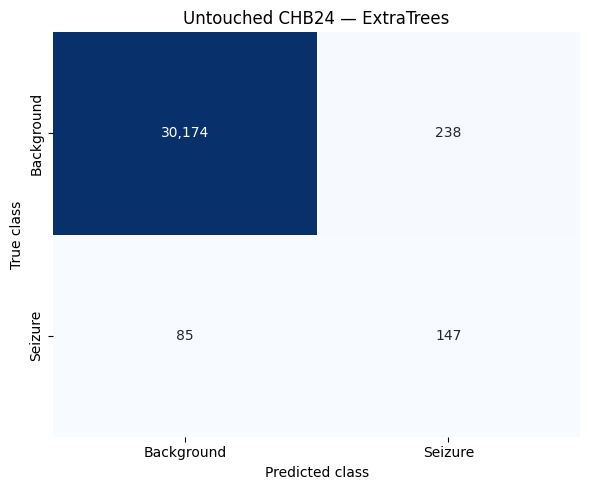

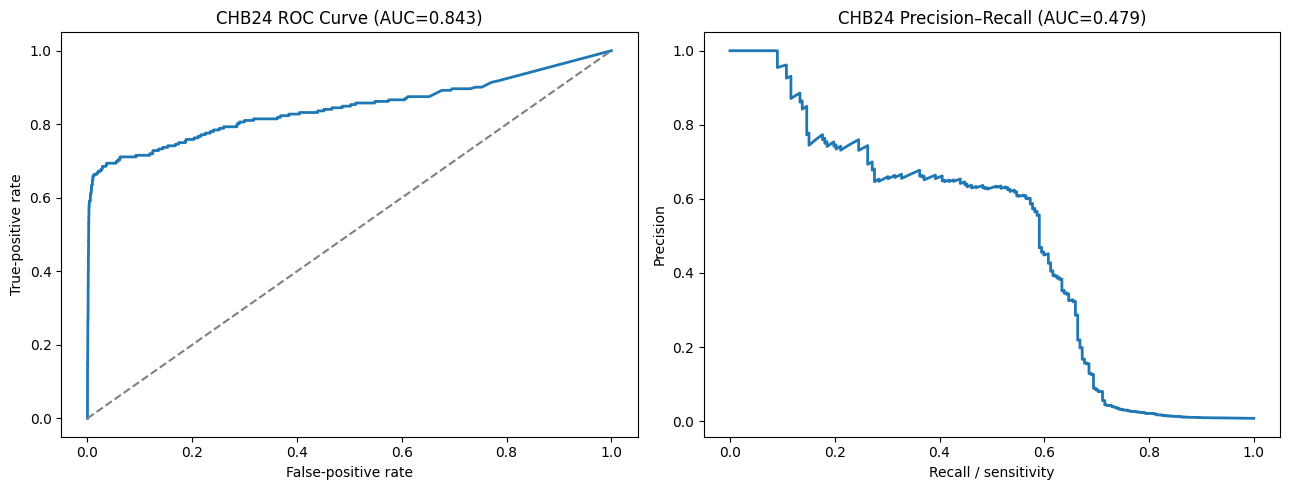

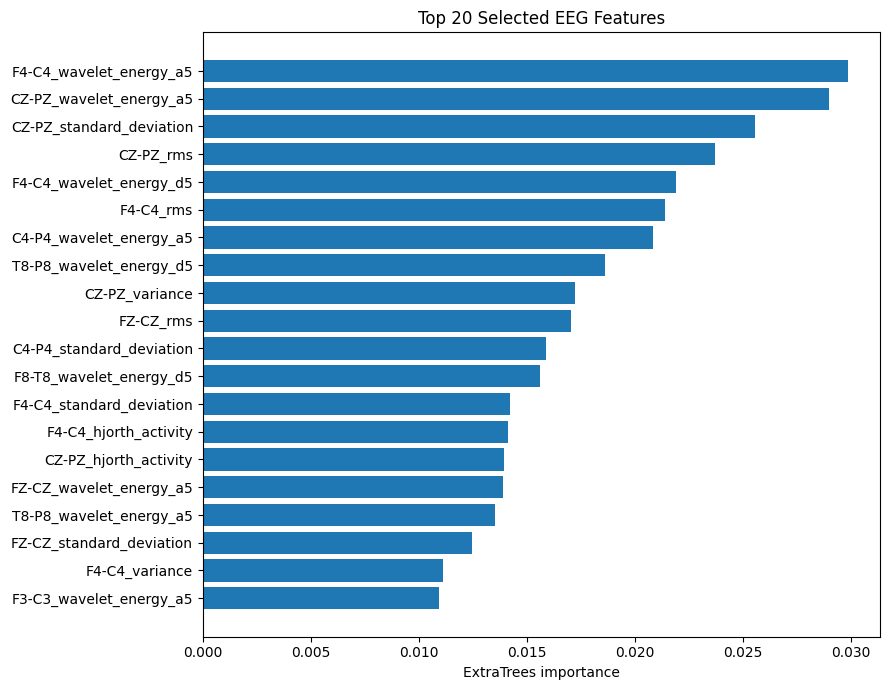


All outputs saved to: /content/drive/MyDrive/EEG/model_results/extratrees_450_features_v1

CELL 5 COMPLETE


In [5]:
# ============================================================
# CELL 5 — FINAL UNTOUCHED CHB24 EVALUATION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    precision_recall_curve,
    roc_curve
)

SELECTED_THRESHOLD = float(
    best_configuration["threshold"]
)

SELECTED_CONSECUTIVE_WINDOWS = int(
    best_configuration[
        "consecutive_windows"
    ]
)

# ------------------------------------------------------------
# Final validation metrics
# ------------------------------------------------------------

validation_probabilities = (
    best_model.predict_proba(
        X_validation_selected
    )[:, 1]
)

final_validation_metrics = (
    classification_metrics(
        y_validation,
        validation_probabilities,
        SELECTED_THRESHOLD
    )
)

validation_alarms = (
    apply_consecutive_rule(
        validation_manifest,
        final_validation_metrics[
            "predictions"
        ],
        SELECTED_CONSECUTIVE_WINDOWS
    )
)

final_validation_events = (
    calculate_event_metrics(
        validation_manifest,
        validation_alarms
    )
)

# ------------------------------------------------------------
# Apply frozen model and threshold to CHB24 once
# ------------------------------------------------------------

test_probabilities = (
    best_model.predict_proba(
        X_test_selected
    )[:, 1]
)

final_test_metrics = classification_metrics(
    y_test,
    test_probabilities,
    SELECTED_THRESHOLD
)

test_alarms = apply_consecutive_rule(
    test_manifest,
    final_test_metrics["predictions"],
    SELECTED_CONSECUTIVE_WINDOWS
)

final_test_events = calculate_event_metrics(
    test_manifest,
    test_alarms
)


def print_results(
    title,
    metrics,
    event_results
):
    print("\n" + "=" * 72)
    print(title)
    print("=" * 72)

    for metric_name in [
        "accuracy",
        "balanced_accuracy",
        "sensitivity",
        "specificity",
        "precision",
        "f1",
        "roc_auc",
        "pr_auc"
    ]:
        print(
            f"{metric_name}: "
            f"{metrics[metric_name]:.6f}"
        )

    print(
        "event_sensitivity:",
        f"{event_results['event_sensitivity']:.6f}"
    )

    print(
        "false_alarms_per_hour:",
        f"{event_results['false_alarms_per_hour']:.6f}"
    )

    print(
        "true_seizure_events:",
        event_results[
            "true_seizure_events"
        ]
    )

    print(
        "detected_seizure_events:",
        event_results[
            "detected_seizure_events"
        ]
    )

    print(
        "false_alarm_events:",
        event_results[
            "false_alarm_events"
        ]
    )

    print(
        "Confusion matrix:",
        f"TN={metrics['tn']},",
        f"FP={metrics['fp']},",
        f"FN={metrics['fn']},",
        f"TP={metrics['tp']}"
    )


print("FROZEN PARAMETERS:")
print(
    json.dumps(
        best_configuration,
        indent=2,
        default=str
    )
)

print_results(
    "VALIDATION RESULTS — CHB10 + CHB23",
    final_validation_metrics,
    final_validation_events
)

print_results(
    "UNTOUCHED TEST RESULTS — CHB24",
    final_test_metrics,
    final_test_events
)

# ------------------------------------------------------------
# Save CHB24 predictions
# ------------------------------------------------------------

test_predictions_table = (
    test_manifest
    .reset_index(drop=True)
    .copy()
)

test_predictions_table[
    "probability"
] = test_probabilities

test_predictions_table[
    "window_prediction"
] = final_test_metrics[
    "predictions"
]

test_predictions_table[
    "event_alarm"
] = test_alarms

test_predictions_table.to_csv(
    OUTPUT_ROOT
    / "chb24_final_predictions.csv",
    index=False
)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

confusion = np.asarray(
    [
        [
            final_test_metrics["tn"],
            final_test_metrics["fp"]
        ],
        [
            final_test_metrics["fn"],
            final_test_metrics["tp"]
        ]
    ]
)

figure, axis = plt.subplots(
    figsize=(6, 5)
)

sns.heatmap(
    confusion,
    annot=True,
    fmt=",d",
    cmap="Blues",
    cbar=False,
    xticklabels=[
        "Background",
        "Seizure"
    ],
    yticklabels=[
        "Background",
        "Seizure"
    ],
    ax=axis
)

axis.set_xlabel("Predicted class")
axis.set_ylabel("True class")

axis.set_title(
    "Untouched CHB24 — ExtraTrees"
)

figure.tight_layout()

figure.savefig(
    OUTPUT_ROOT
    / "chb24_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# ROC and Precision–Recall curves
# ------------------------------------------------------------

false_positive_rate, (
    true_positive_rate
), _ = roc_curve(
    y_test,
    test_probabilities
)

precision_values, (
    recall_values
), _ = precision_recall_curve(
    y_test,
    test_probabilities
)

figure, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

axes[0].plot(
    false_positive_rate,
    true_positive_rate,
    linewidth=2
)

axes[0].plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray"
)

axes[0].set_xlabel(
    "False-positive rate"
)

axes[0].set_ylabel(
    "True-positive rate"
)

axes[0].set_title(
    "CHB24 ROC Curve "
    f"(AUC="
    f"{final_test_metrics['roc_auc']:.3f})"
)

axes[1].plot(
    recall_values,
    precision_values,
    linewidth=2
)

axes[1].set_xlabel(
    "Recall / sensitivity"
)

axes[1].set_ylabel(
    "Precision"
)

axes[1].set_title(
    "CHB24 Precision–Recall "
    f"(AUC="
    f"{final_test_metrics['pr_auc']:.3f})"
)

figure.tight_layout()

figure.savefig(
    OUTPUT_ROOT
    / "chb24_roc_precision_recall.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Training-feature importance
# ------------------------------------------------------------

importance_table = pd.DataFrame(
    {
        "feature": selected_feature_names,
        "importance": (
            best_model.feature_importances_
        )
    }
).sort_values(
    "importance",
    ascending=False
)

importance_table.to_csv(
    OUTPUT_ROOT
    / "feature_importance.csv",
    index=False
)

top_features = importance_table.head(
    20
).sort_values(
    "importance",
    ascending=True
)

figure, axis = plt.subplots(
    figsize=(9, 7)
)

axis.barh(
    top_features["feature"],
    top_features["importance"]
)

axis.set_xlabel(
    "ExtraTrees importance"
)

axis.set_title(
    "Top 20 Selected EEG Features"
)

figure.tight_layout()

figure.savefig(
    OUTPUT_ROOT
    / "top_20_feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "\nAll outputs saved to:",
    OUTPUT_ROOT
)

print("\nCELL 5 COMPLETE")